# Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import HDMapsDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 20


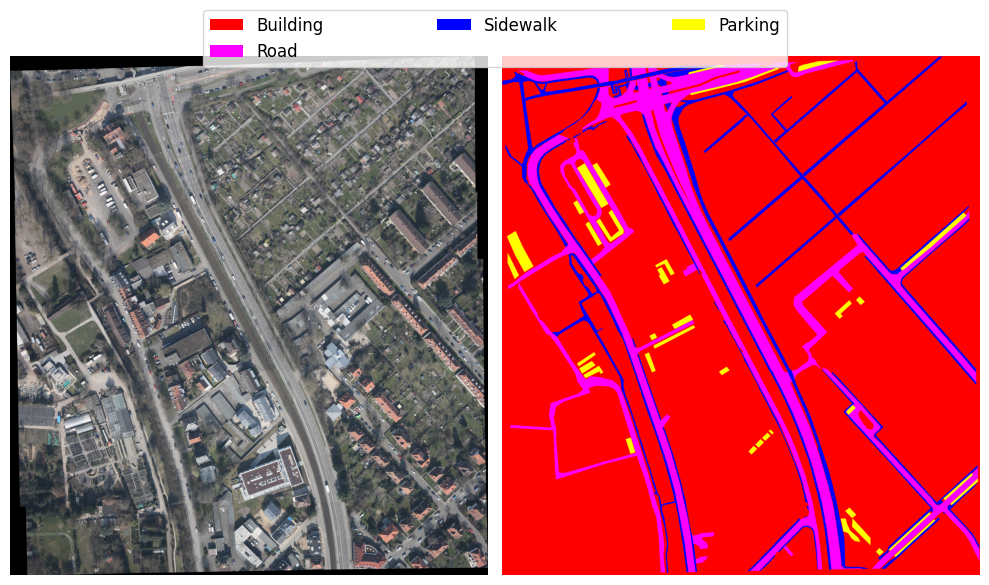

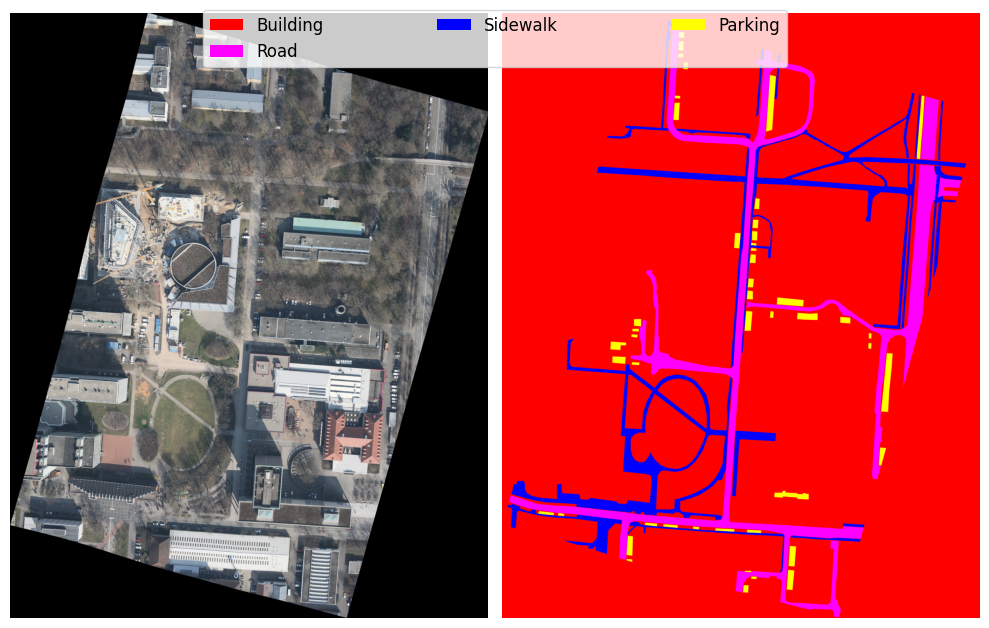

In [8]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/HDMaps/"
}
dataset = HDMapsDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);

In [9]:
dataset.data_distribution_table()

,Number of pixels
Building,596951756.0
Road,38912855.0
Sidewalk,15700894.0
Parking,9393318.0


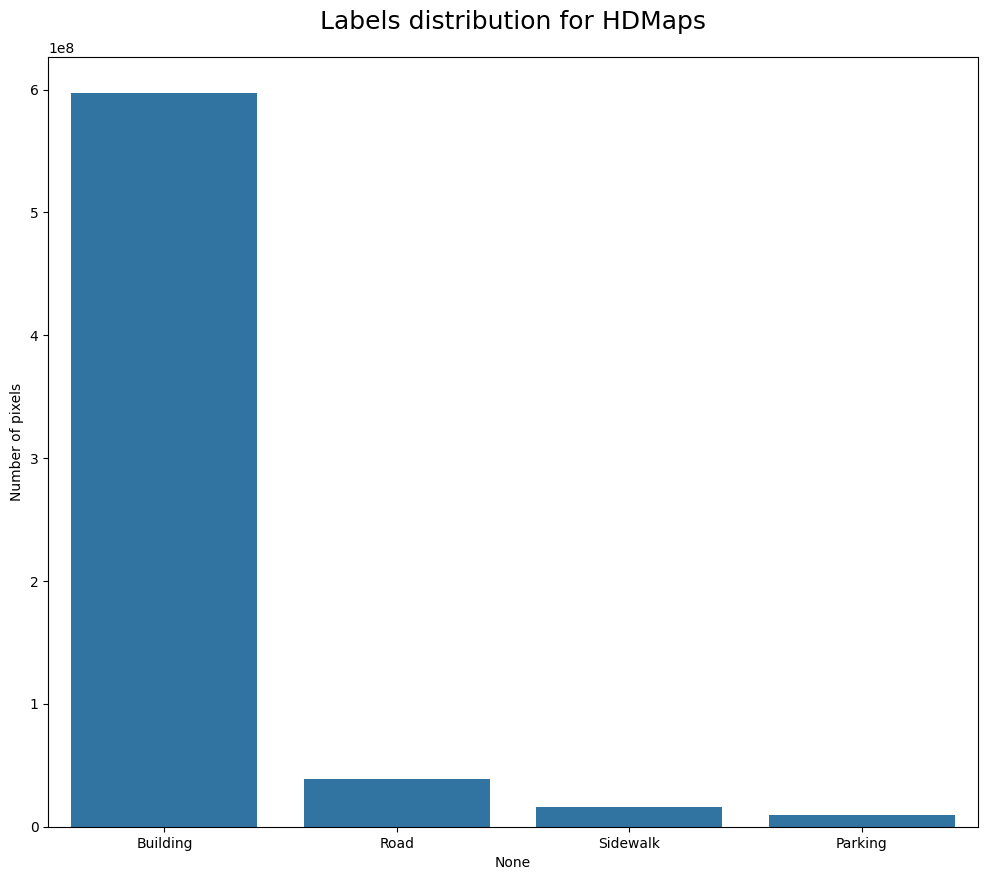

In [10]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/HDMaps",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = HDMapsDataset(train_dataset_config)
len(train_dataset)

20

## Create the model

In [5]:
epochs = 5
model_directory = "/home/dragik/data/FAIR_EO/HDMaps"
model_config = {
    "num_classes": 4, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-05 07:52:10,576 INFO Starting training.
training: 100%|██████████| 5/5 [35:08<00:00, 421.64s/it]  
2025-03-05 08:27:18,877 INFO epoch: 1, time: 2108, loss:  0.60483
testing on train set: 100%|██████████| 5/5 [38:15<00:00, 459.15s/it]   
2025-03-05 09:05:36,715 INFO IOU:0.45744507638977494, IOU mean:0.21435888826878088, IOU per Class:[8.08673253e-01 4.34104615e-02 5.35475234e-04 4.81636357e-03]
training: 100%|██████████| 5/5 [31:48<00:00, 381.72s/it]
2025-03-05 09:37:25,327 INFO epoch: 2, time: 1909, loss:  0.59206
testing on train set: 100%|██████████| 5/5 [35:31<00:00, 426.32s/it]   
2025-03-05 10:12:56,925 INFO IOU:0.42723838819956456, IOU mean:0.19979892705651087, IOU per Class:[0.74171073 0.0474157  0.00131617 0.0087531 ]
training: 100%|██████████| 5/5 [38:03<00:00, 456.66s/it]   
2025-03-05 10:51:00,252 INFO epoch: 3, time: 2284, loss:  0.57868
testing on train set: 100%|██████████| 5/5 [34:15<00:00, 411.01s/it]   
2025-03-05 11:25:15,301 INFO IOU:0.4220471268667616, IOU m

## Evaluate the model

In [7]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/HDMaps/test",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = HDMapsDataset(test_dataset_config)
len(test_dataset)

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/HDMaps/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-03-05 13:39:28,018 INFO Loading checkpoint /home/dragik/data/FAIR_EO/HDMaps/checkpoint.pth.tar
2025-03-05 13:39:28,468 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/HDMaps/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 3/3 [16:16<00:00, 325.65s/it]


[{'IOU': 0.40904582019154306,
  'IOU mean': 0.1955126585622144,
  'IOU per Class': array([0.71922533, 0.05315655, 0.00132332, 0.00834544])}]

## Predictions

2025-03-10 09:39:29,776 INFO Loading checkpoint /home/dragik/data/FAIR_EO/HDMaps/checkpoint.pth.tar


2025-03-10 09:39:30,378 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/HDMaps/checkpoint.pth.tar at epoch 6


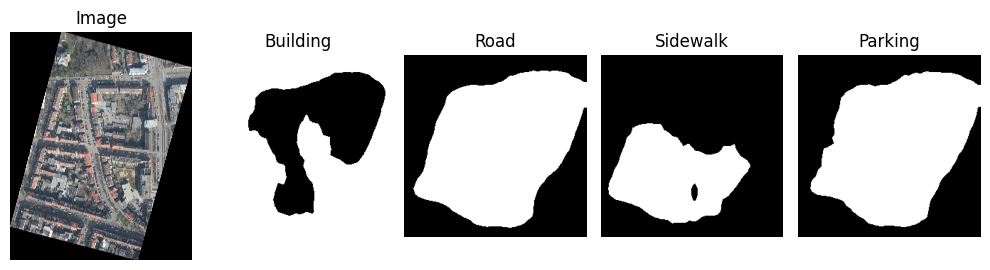

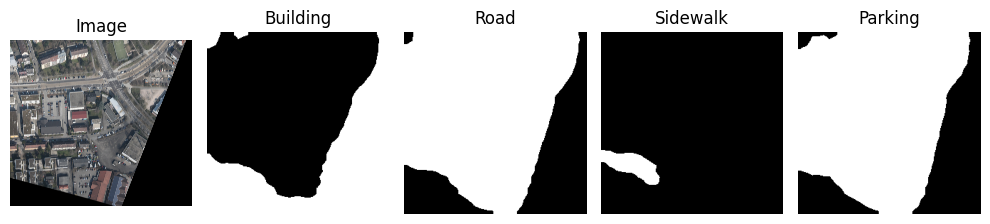

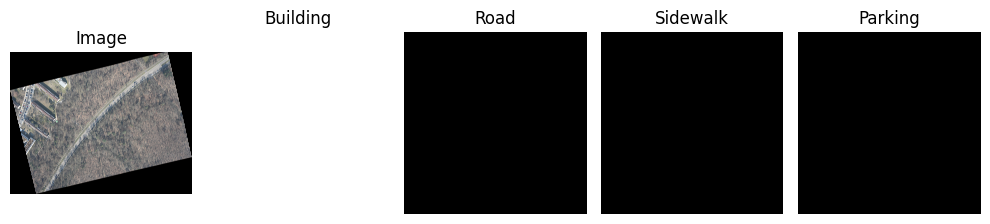

In [6]:
model_path = "/home/dragik/data/FAIR_EO/HDMaps/checkpoint.pth.tar"
labels = ["Building","Road","Sidewalk","Parking"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/HDMaps/test/images/KTesting_00.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/HDMaps/test/images/KTraining_02.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/HDMaps/test/images/KTraining_18.jpg')
fig = model.predict_masks(image, labels, transform)